<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Continuous Distributions

_Author:_ Tim Book

### Learning Objectives
*After this lesson, students will be able to:*
- Describe the difference between pmfs and pdfs.
- Use probability density functions (pdfs) and cumulative distribution functions (CDFs) to find probabilities of events.
- Use the Empirical Rule / 68-95-99.7 Rule to calculate probabilities of events for a Normal distribution.
- Describe and give examples of when to use the following distributions: Continuous Uniform, Normal, $t$, Exponential, Gamma, and Beta.

In [1]:
# Our imports.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import seaborn as sns

# Set our seed.
np.random.seed(42)

## `scipy.stats`
SciPy is a scientific computing library. It contains various functions for matrix algebra, calculus, statistics, and probability. The `stats` submodule is what we'll need today!

## The Normal Distribution
Let's create a normal random variable!

$$ X \sim Normal(7,2) $$

In [2]:
# X ~ Normal(7, 2)
X = stats.norm(7, 2)

Let's sample some observations from $X$ and plot. What happens when we increase $n$?

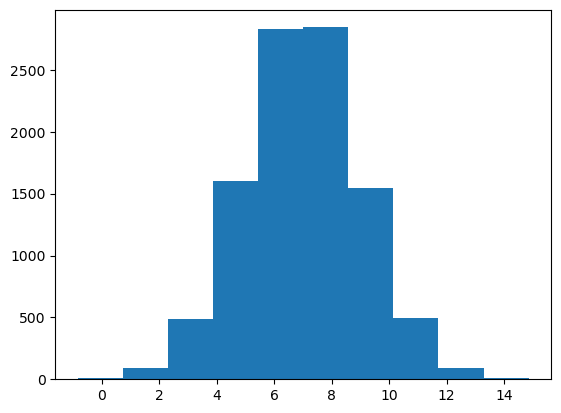

In [3]:
# Let's randomly generate 5, 10, 100, 1,000, and 10,000 observations from this distribution.
n = 10000
x_values = X.rvs(n)

# Plot a histogram.
plt.hist(x_values);

In [4]:
# What's P(X<=5)?
X.cdf(5)

0.15865525393145707

In [5]:
# What's P(X>5)?
1 - X.cdf(5)

0.8413447460685429

In [6]:
# What's P(5<=X<=9)?
X.cdf(9) - X.cdf(5)

# What do we *think* it should be? Why?

0.6826894921370859

## The Exponential Distribution
Let's create an Exponential random variable! Specifically, suppose I receive a spam email every 8 hours.

$$ Y \sim Exponential(8) $$

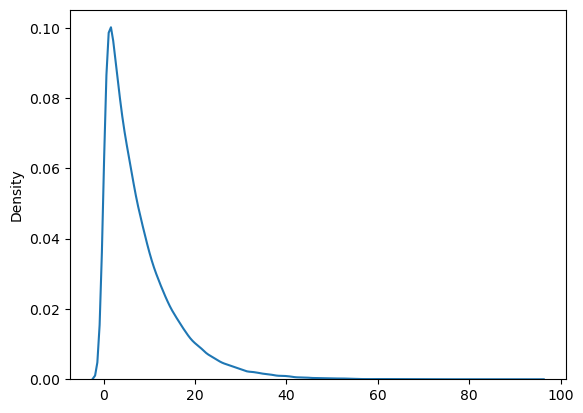

In [7]:
# Y ~ Exponential(8)
Y = stats.expon(scale=8)

# Randomly generate 100,000 observations from Y.
n = 100_000
y_values = Y.rvs(n)

# Plot a Kernel Density Estimate (kde, a smooth curve of my observations).
sns.kdeplot(y_values);

In [8]:
# What's the probability that I receive a spam email in the next 20 hours?
Y.cdf(20)

0.9179150013761012

In [9]:
# What's the probability that I don't receive a spam email in the next 8 hours?
1 - Y.cdf(8)

0.36787944117144233

## Calculating probabilities with CDFs

### Problem 1
Suppose every morning you wait for the bus. Buses in your area come about every 15 minutes. What's the probability you'll be waiting for more than 20?

In [10]:
W = stats.expon(scale=15)

In [11]:
1 - W.cdf(20)

0.2635971381157267

### Problem 2
Suppose $X \sim N(7, 2)$. What is $P(5.5 \le X \le 7.3)$?

In [12]:
X = stats.norm(7, 2)
a = 5.5
b = 7.3

X.cdf(b) - X.cdf(a)

0.3329903399933743

### BONUS: Problem 3
Suppose:

* $X \sim \text{Exp}(\beta = 5)$
* $Y \sim U(0, 10)$
* $Z \sim N(0, 1)$

And they're all mutually independent.

In [13]:
# Define X, Y, Z here:
X = stats.expon(scale=5)
Y = stats.uniform(0, 10)
Z = stats.norm(0, 1)

#### 3a
What is $P(X > 3 \cap Y < 8 \cap Z > 1.5)$?

_Reminder:_ The $\cap$ symbol means "and"

In [14]:
p1 = 1 - X.cdf(3)
p2 = Y.cdf(8)
p3 = 1 - Z.cdf(1.5)

p1*p2*p3

0.029331655544979945

#### 3b
What is $P(X > 3 \cup Y < 8)$?

_Reminder:_ The $\cup$ symbol means "or"

In [15]:
p1 = 1 - X.cdf(3)
p2 = Y.cdf(8)

p1 + p2 - p1*p2

0.9097623272188053

#### 3c (a multistep problem!)

What is $P(X > 3 \cap (Y < 8 \cup Z > 1.5)$?

In [16]:
p1 = 1 - X.cdf(3)
p2 = Y.cdf(8)
p3 = 1 - Z.cdf(1.5)

a = p1
b = p2 + p3 - p2*p3

ans = a*b
ans

0.4463822227614662

#### BONUS: A neat visual with two distributions...

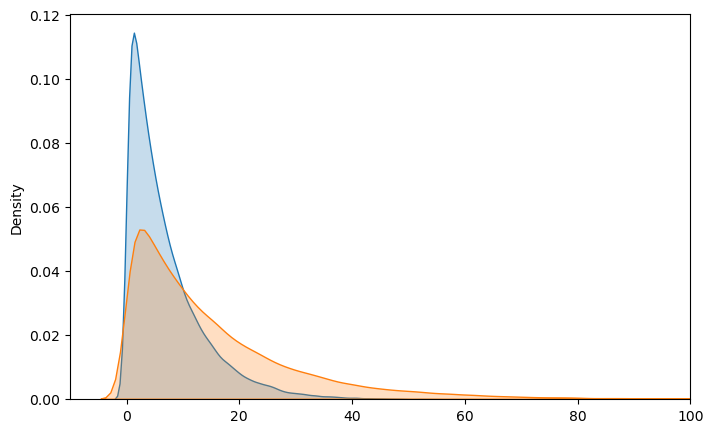

In [17]:
X = stats.expon(scale=7)
Y = stats.expon(scale=15)

n = 100_000
xs = X.rvs(n)
ys = Y.rvs(n)

# Smoothed out histogram = "density plot" or "KDE plot"
# sns.densityplot()
plt.figure(figsize=(8, 5))
sns.kdeplot(xs, fill=True)
sns.kdeplot(ys, fill=True)
plt.xlim(-10, 100);